# EDA: Telco Customer Churn

**Goal:** understand the data 

Questions we answer:
1. What does the data look like, and is it clean?
2. How imbalanced is the target?
3. Which features seem related to churn?
4. Are there groups where churn differs strongly (fairness check, chapter 13)?
5. What decisions does this imply for `src/features/preprocess.py`?

>

In [2]:
import math
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)

DATA_PATH = Path("../data/raw/telco_churn.csv")
FIG_DIR = Path("../docs/eda")
FIG_DIR.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(DATA_PATH)
print("Shape:", df.shape)

Shape: (7043, 21)


## 1. Overview

In [3]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [5]:
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
customerID,7043,7043,7590-VHVEG,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gender,7043,2,Male,3555,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SeniorCitizen,7043.0,NaN,NaN,NaN,0.162147,0.368612,0.0,0.0,0.0,0.0,1.0
Partner,7043,2,No,3641,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Dependents,7043,2,No,4933,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tenure,7043.0,NaN,NaN,NaN,32.371149,24.559481,0.0,9.0,29.0,55.0,72.0
PhoneService,7043,2,Yes,6361,NaN,NaN,NaN,NaN,NaN,NaN,NaN
MultipleLines,7043,3,No,3390,NaN,NaN,NaN,NaN,NaN,NaN,NaN
InternetService,7043,3,Fiber optic,3096,NaN,NaN,NaN,NaN,NaN,NaN,NaN
OnlineSecurity,7043,3,No,3498,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 2. Data quality

In [19]:
print("Duplicated rows:", df.duplicated().sum())
print("Duplicated customerID:", df["customerID"].duplicated().sum())

print("\nNaN per column (only columns with NaN):")
nan_counts = df.isna().sum()
print(nan_counts[nan_counts > 0] if (nan_counts > 0).any() else "none")

print("\nBlank strings per column (only columns with blanks):")
blank_counts = df.apply(lambda col: col.astype(str).str.strip().eq("").sum())
print(blank_counts[blank_counts > 0] if (blank_counts > 0).any() else "none")

Duplicated rows: 0
Duplicated customerID: 0

NaN per column (only columns with NaN):
none

Blank strings per column (only columns with blanks):
TotalCharges    11
dtype: int64


In [20]:
total_numeric = pd.to_numeric(df["TotalCharges"], errors="coerce")
bad_rows = df[total_numeric.isna()]
print("Rows where TotalCharges is not a number:", len(bad_rows))
bad_rows[["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]]

Rows where TotalCharges is not a number: 11


,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,,No
753,3115-CZMZD,0,20.25,,No
936,5709-LVOEQ,0,80.85,,No
1082,4367-NUYAO,0,25.75,,No
1340,1371-DWPAZ,0,56.05,,No
3331,7644-OMVMY,0,19.85,,No
3826,3213-VVOLG,0,25.35,,No
4380,2520-SGTTA,0,20.00,,No
5218,2923-ARZLG,0,19.70,,No
6670,4075-WKNIU,0,73.35,,No


In [21]:
eda = df.copy()
eda["TotalCharges"] = pd.to_numeric(eda["TotalCharges"], errors="coerce")
eda["churn_flag"] = (eda["Churn"] == "Yes").astype(int)
eda.shape

(7043, 22)

## 3. Target distribution

Churn
No     5174
Yes    1869
Name: count, dtype: int64
Churn
No     0.735
Yes    0.265
Name: count, dtype: float64


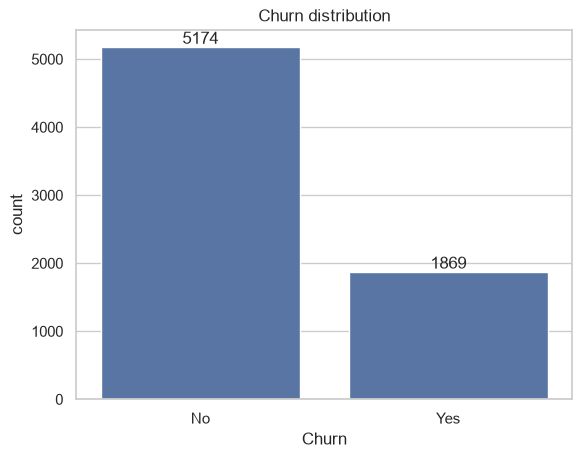

In [9]:
counts = eda["Churn"].value_counts()
print(counts)
print((counts / len(eda)).round(3))

ax = sns.countplot(data=eda, x="Churn")
ax.set_title("Churn distribution")
for container in ax.containers:
    ax.bar_label(container)
plt.savefig(FIG_DIR / "target_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

## 4. Numeric features

In [10]:
num_cols = ["tenure", "MonthlyCharges", "TotalCharges"]
eda.groupby("Churn")[num_cols].median()

,tenure,MonthlyCharges,TotalCharges
Churn,,,
No,38.0,64.425,1683.60
Yes,10.0,79.650,703.55


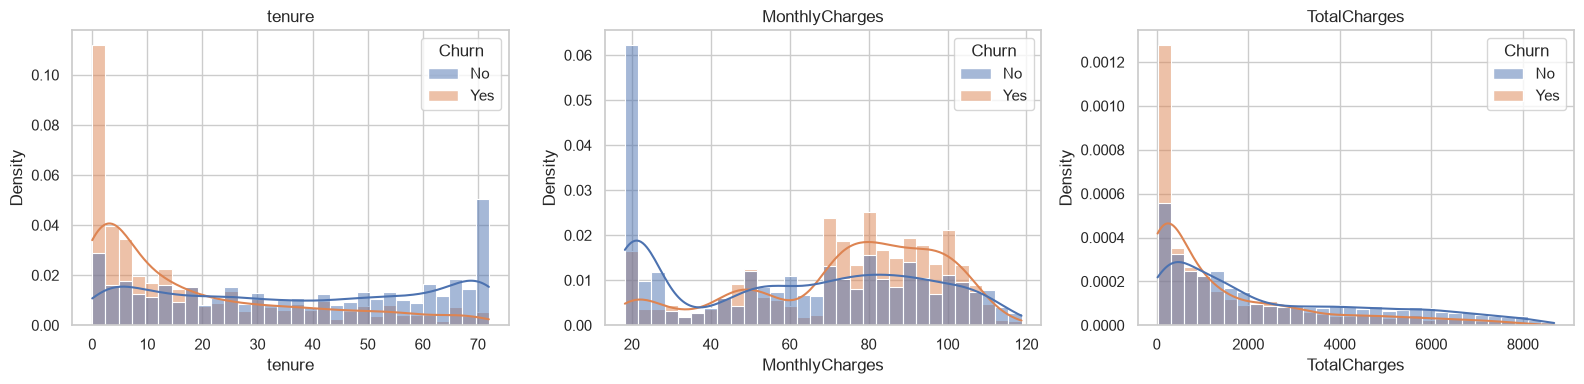

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, num_cols):
    sns.histplot(
        data=eda, x=col, hue="Churn", bins=30, kde=True,
        stat="density", common_norm=False, ax=ax,
    )
    ax.set_title(col)
plt.tight_layout()
plt.savefig(FIG_DIR / "numeric_distributions.png", dpi=150, bbox_inches="tight")
plt.show()

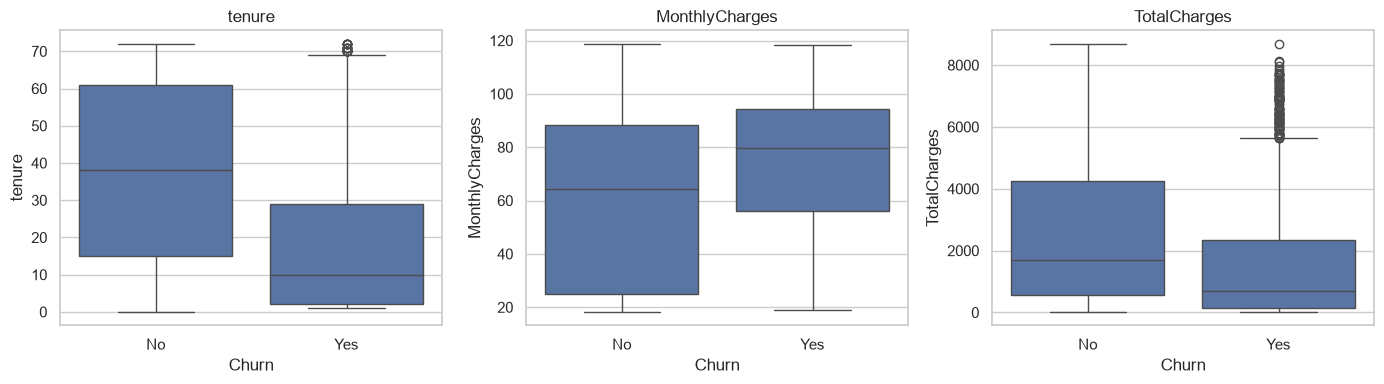

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, col in zip(axes, num_cols):
    sns.boxplot(data=eda, x="Churn", y=col, ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

             mean  count
tenure_bin              
0-6         0.529   1481
7-12        0.359    705
13-24       0.287   1024
25-48       0.204   1594
49-72       0.095   2239


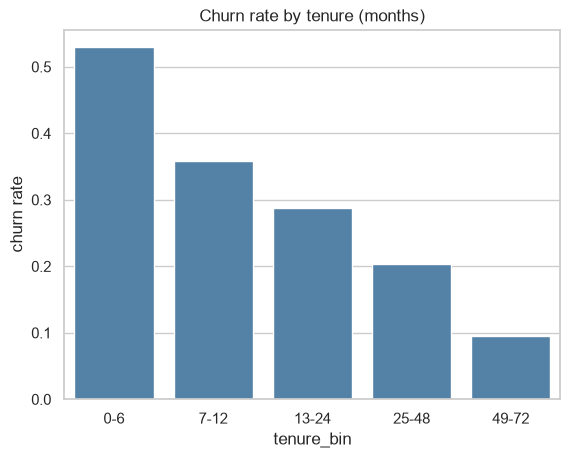

In [13]:
eda["tenure_bin"] = pd.cut(
    eda["tenure"],
    bins=[-1, 6, 12, 24, 48, 72],
    labels=["0-6", "7-12", "13-24", "25-48", "49-72"],
)
rate = eda.groupby("tenure_bin", observed=True)["churn_flag"].agg(["mean", "count"])
print(rate.round(3))

ax = sns.barplot(x=rate.index.astype(str), y=rate["mean"], color="steelblue")
ax.set_title("Churn rate by tenure (months)")
ax.set_ylabel("churn rate")
plt.savefig(FIG_DIR / "churn_by_tenure.png", dpi=150, bbox_inches="tight")
plt.show()

## 5. Categorical features



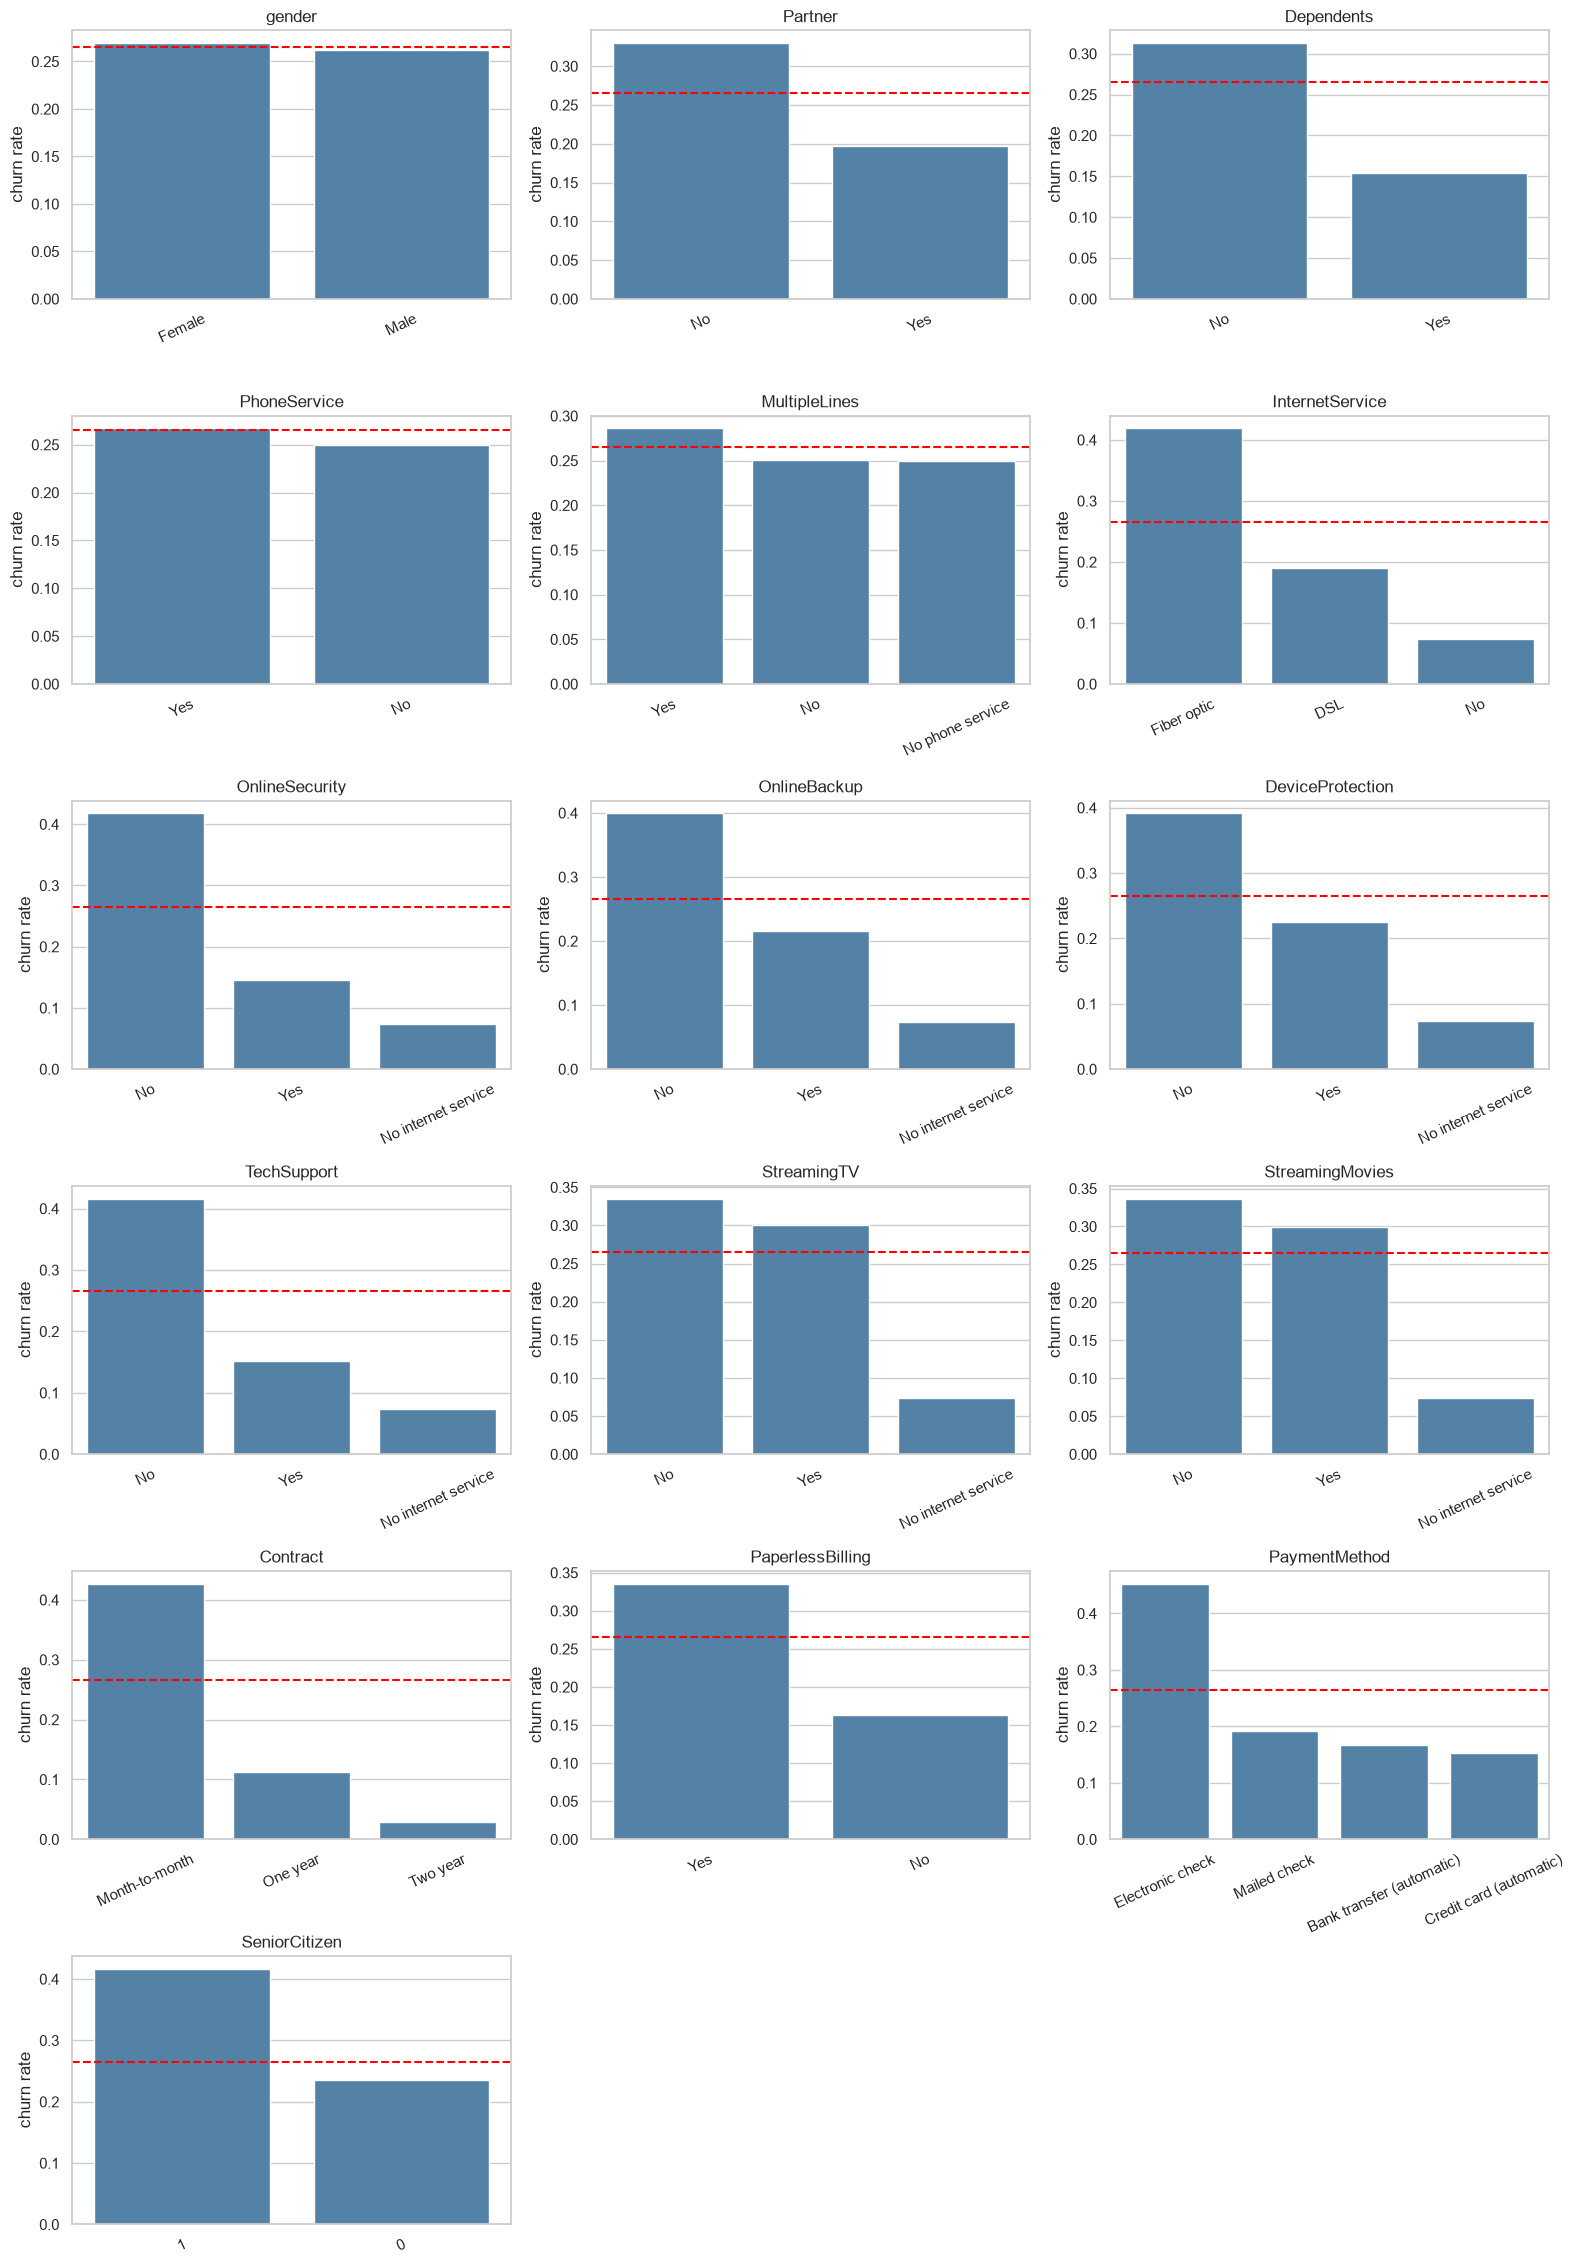

In [22]:
cat_cols = [
    c for c in eda.select_dtypes(exclude="number").columns
    if c not in ["customerID", "Churn", "tenure_bin"]
]
cat_cols.append("SeniorCitizen")  # numeric 0/1 but really a category

n = len(cat_cols)
ncols = 3
nrows = math.ceil(n / ncols)
global_rate = eda["churn_flag"].mean()

fig, axes = plt.subplots(nrows, ncols, figsize=(16, 3.8 * nrows))
axes = axes.ravel()
for ax, col in zip(axes, cat_cols):
    rate = eda.groupby(col)["churn_flag"].mean().sort_values(ascending=False)
    sns.barplot(x=rate.index.astype(str), y=rate.values, ax=ax, color="steelblue")
    ax.axhline(global_rate, color="red", linestyle="--")
    ax.set_title(col)
    ax.set_ylabel("churn rate")
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=25)
for ax in axes[n:]:
    ax.axis("off")
plt.tight_layout()
plt.savefig(FIG_DIR / "churn_by_category.png", dpi=150, bbox_inches="tight")
plt.show()

In [23]:
# Cardinality and category sizes: tiny categories give unreliable rates
for col in cat_cols:
    print(f"{col}: {eda[col].nunique()} values -> {eda[col].value_counts().to_dict()}")

gender: 2 values -> {'Male': 3555, 'Female': 3488}
Partner: 2 values -> {'No': 3641, 'Yes': 3402}
Dependents: 2 values -> {'No': 4933, 'Yes': 2110}
PhoneService: 2 values -> {'Yes': 6361, 'No': 682}
MultipleLines: 3 values -> {'No': 3390, 'Yes': 2971, 'No phone service': 682}
InternetService: 3 values -> {'Fiber optic': 3096, 'DSL': 2421, 'No': 1526}
OnlineSecurity: 3 values -> {'No': 3498, 'Yes': 2019, 'No internet service': 1526}
OnlineBackup: 3 values -> {'No': 3088, 'Yes': 2429, 'No internet service': 1526}
DeviceProtection: 3 values -> {'No': 3095, 'Yes': 2422, 'No internet service': 1526}
TechSupport: 3 values -> {'No': 3473, 'Yes': 2044, 'No internet service': 1526}
StreamingTV: 3 values -> {'No': 2810, 'Yes': 2707, 'No internet service': 1526}
StreamingMovies: 3 values -> {'No': 2785, 'Yes': 2732, 'No internet service': 1526}
Contract: 3 values -> {'Month-to-month': 3875, 'Two year': 1695, 'One year': 1473}
PaperlessBilling: 2 values -> {'Yes': 4171, 'No': 2872}
PaymentMethod: 

## 6. Correlations (numeric)

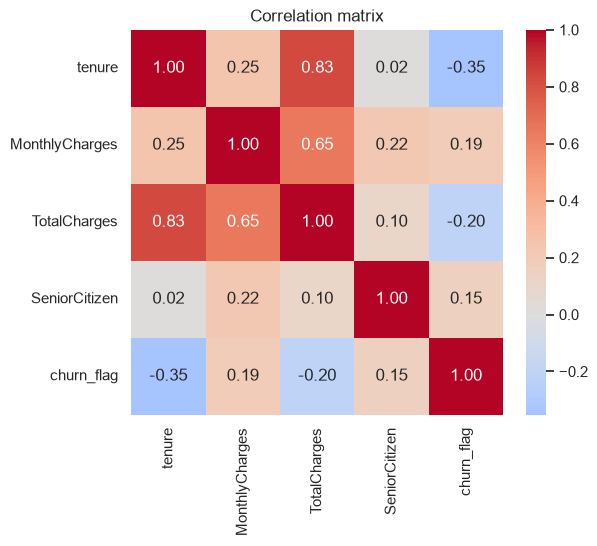

In [16]:
corr_cols = ["tenure", "MonthlyCharges", "TotalCharges", "SeniorCitizen", "churn_flag"]
corr = eda[corr_cols].corr()

plt.figure(figsize=(6, 5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation matrix")
plt.savefig(FIG_DIR / "correlation.png", dpi=150, bbox_inches="tight")
plt.show()

In [17]:
expected = eda["tenure"] * eda["MonthlyCharges"]
print("Correlation TotalCharges vs tenure*MonthlyCharges:",
      round(eda["TotalCharges"].corr(expected), 3))

Correlation TotalCharges vs tenure*MonthlyCharges: 1.0


## 7. Fairness preview


In [18]:
for col in ["gender", "SeniorCitizen"]:
    print(eda.groupby(col)["churn_flag"].agg(["mean", "count"]).round(3), "\n")

         mean  count
gender              
Female  0.269   3488
Male    0.262   3555 

                mean  count
SeniorCitizen              
0              0.236   5901
1              0.417   1142 

